# Complementando nossas informações!

Acabamos de ver uma árvore construída com um único marcador, o 16S. Por que não parar aí?

Um único gene tem limitações:

- **Pouco sinal:** o 16S tem cerca de 1.500 posições, e só uma parte delas varia de forma informativa. Ramos curtos e profundos ficam mal resolvidos.
- **Saturação:** em distâncias evolutivas grandes, a mesma posição pode ter mudado várias vezes, apagando o sinal antigo.
- **A árvore do gene não é necessariamente a árvore das espécies:** um gene pode ter sido transferido horizontalmente ou ter cópias com histórias diferentes. Com um único gene, não temos como perceber isso.

Uma solução é usar **vários marcadores conservados ao longo de grandes distâncias evolutivas** e concatená-los. Esses marcadores precisam ser **ortólogos**, ou seja, a separação do gene A da espécie 1 e do gene A da espécie 2 precisa ser um **evento de especiação**.

Às vezes um grupo de genes ortólogos não é de cópia única, e precisamos tomar uma decisão. Aqui, como os marcadores foram selecionados com base na literatura, escolhemos a cópia mais longa quando o gene tinha mais de uma cópia.


Nós selecionamos os marcadores de proteínas ribossomais escolhidos por Antunes et al. (2016), são ao todo 47 proteínas ribossomais

Embora o programa Bakta nos permita ter uma ideia de onde estão os genes e qual é o produto que eles geram, a simples anotação não nos garante que os genes sejam ortólogos.

Logo, fazemos o uso de um outro programa chamado Orthofinder.

O Orthofinder agrupa as proteínas dos genomas fornecidos à ele e realiza etapas de agrupamento que levarão à identificação de grupos de ortólogos.

Um ponto a se ressaltar é que esses grupos de ortólogos devem ser inspecionados, pode ocorrer do Orthofinder separar em dois grupos de ortólogos distintos os nossos genes-alvo

# Materiais

Os arquivos `selribs_df.pkl`, `trimribs_df.pkl` e `ribconcat_df.pkl` contêm os nossos alinhamentos dentro de uma estrutura chamada DataFrame, essa estrutura é semelhante a uma tabela. Os dois primeiros são dicionários com um DataFrame por marcador; o último é um DataFrame com o alinhamento concatenado.

O processo de checagem dos orthogroups e de construção dos alinhamentos já foi realizado na preparação dos dados e não será reexecutado aqui.

## 1. Carregamento e validação

Carregamos as versões portáteis dos arquivos de curadoria. Modifique a variável "DATA_DIR" se necessário.

In [1]:
from pathlib import Path
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from IPython.display import display, clear_output
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def localizar_projeto():
    pasta = Path.cwd().resolve()
    for candidato in (pasta, *pasta.parents):
        if (candidato / "atividade").is_dir() and (candidato / "dados").is_dir():
            return candidato
    raise FileNotFoundError("Abra o JupyterLab na raiz do projeto ou em atividade/.")

PROJECT = localizar_projeto()
DATA_DIR = PROJECT / "dados"
RESULT_DIR = PROJECT / "resultados"
RESULT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT / "scripts"))
from alinhamentos import visualizador, arquivos_de_alinhamento
print("Projeto:", PROJECT)

selribs = pd.read_pickle(DATA_DIR / 'selribs_df.pkl')
trimribs = pd.read_pickle(DATA_DIR / 'trimribs_df.pkl')
ribconcat = pd.read_pickle(DATA_DIR / 'ribconcat_df.pkl')
assert isinstance(selribs, dict) and isinstance(trimribs, dict)
assert set(selribs) == set(trimribs)
assert all(isinstance(df, pd.DataFrame) for df in selribs.values())
assert all(isinstance(df, pd.DataFrame) for df in trimribs.values())
assert isinstance(ribconcat, pd.DataFrame)

N_GENOMES = 229

def metrics(df):
    """Número de genomas, comprimento do alinhamento e % de gaps de um marcador."""
    seqs = df['sequence'].dropna().astype(str)
    if seqs.empty:
        raise ValueError('Marcador sem sequências')
    lengths = seqs.str.len().unique()
    if len(lengths) != 1:
        raise ValueError(f'Comprimentos diferentes: {lengths}')
    total = len(seqs) * int(lengths[0])
    return {'genomas': df['assembly'].nunique(), 'posicoes': int(lengths[0]),
            'gaps_%': 100 * seqs.str.count('-').sum() / total}

rows = {}
for m in selribs:
    antes, depois = metrics(selribs[m]), metrics(trimribs[m])
    rows[m] = {'genomas': antes['genomas'],
               'cobertura_%': 100 * antes['genomas'] / N_GENOMES,
               'posicoes_antes': antes['posicoes'],
               'posicoes_depois': depois['posicoes'],
               'gaps_antes_%': antes['gaps_%'],
               'gaps_depois_%': depois['gaps_%']}
summary = pd.DataFrame.from_dict(rows, orient='index')
summary.index.name = 'marcador'
assert ribconcat.assembly.nunique() == N_GENOMES
print(f'{len(selribs)} marcadores, {N_GENOMES} genomas no alinhamento concatenado')
display(summary.head())


Projeto: /home/marialuiza/Luiza/Colabs/bacillus/migração_git/claude/Bacillotav4
47 marcadores, 229 genomas no alinhamento concatenado


,genomas,cobertura_%,posicoes_antes,posicoes_depois,gaps_antes_%,gaps_depois_%
marcador,,,,,,
rplU,227,99.126638,303,102,65.371251,0.129567
rpmE,222,96.943231,205,83,64.862668,15.559535
rpmF,213,93.013100,90,56,34.371414,0.251509
rpsA,224,97.816594,1054,441,61.719809,12.249960
rpsF,228,99.563319,120,94,19.850146,0.261292


## 2. Cobertura dos marcadores e efeito do trimAl

Para cada marcador, registramos o número de genomas com sequência, o comprimento do alinhamento e a fração de gaps. **Cobertura aqui indica presença de sequência no conjunto de alinhamentos**, não presença/ausência biológica inequívoca do gene.

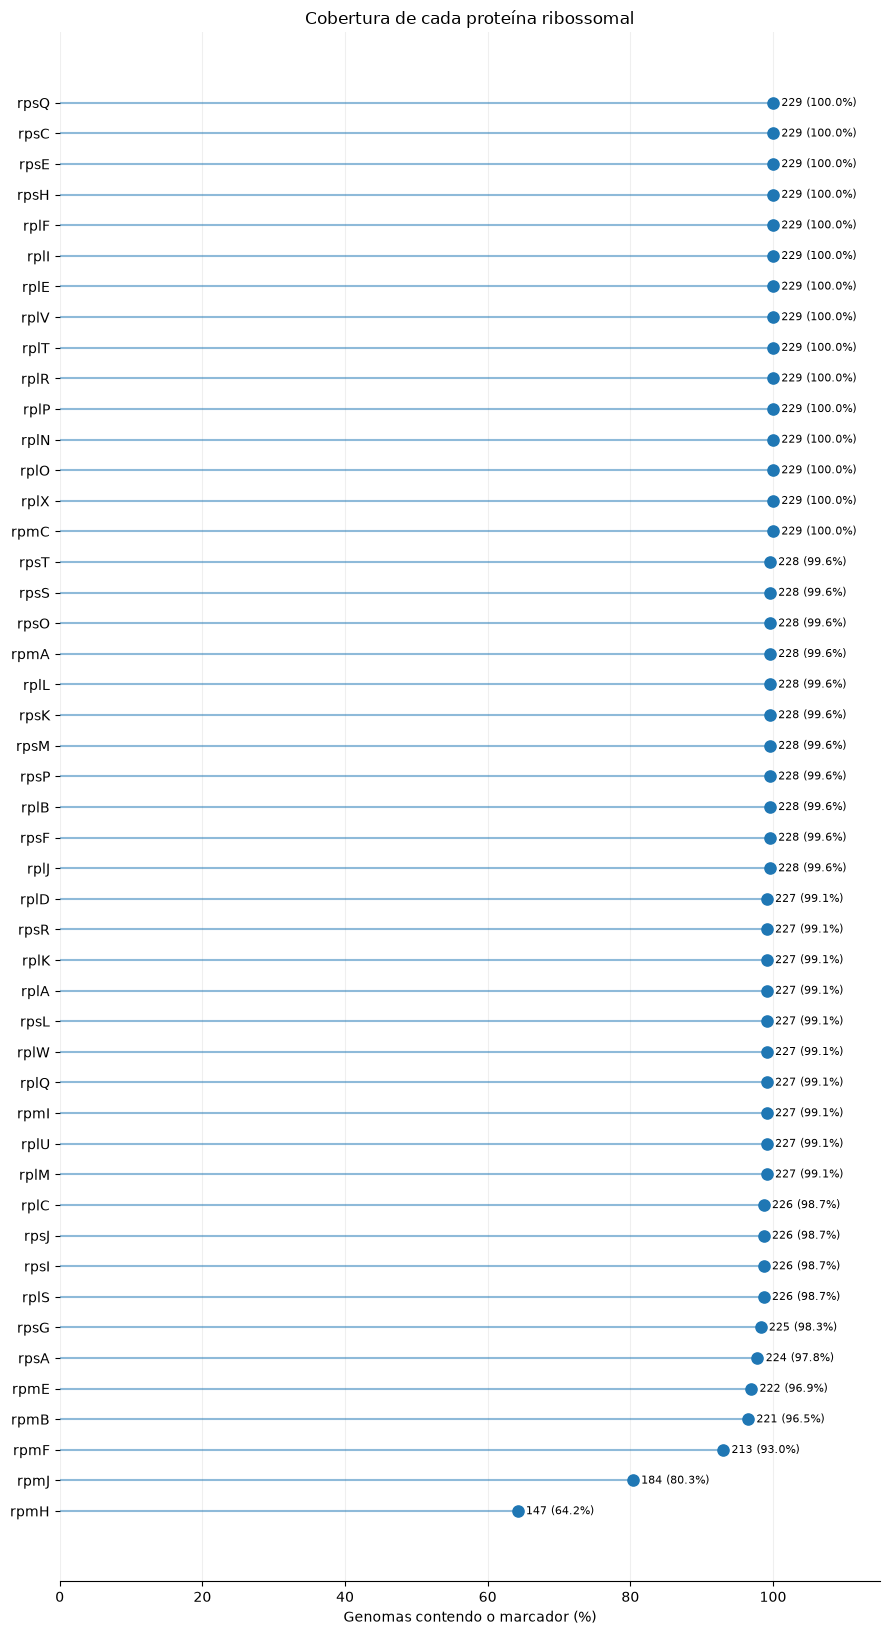

In [2]:
plot_df = summary.sort_values('cobertura_%')
fig, ax = plt.subplots(figsize=(9, max(4, len(plot_df) * 0.35)))
y = np.arange(len(plot_df))
ax.hlines(y, 0, plot_df['cobertura_%'], alpha=.5)
ax.scatter(plot_df['cobertura_%'], y, s=65, zorder=3)
for pos, (_, row) in enumerate(plot_df.iterrows()):
    ax.annotate(f"{int(row['genomas'])} ({row['cobertura_%']:.1f}%)",
                (row['cobertura_%'], pos), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=8)
ax.set_yticks(y, labels=plot_df.index)
ax.set_xlim(0, 115)
ax.set_xlabel('Genomas contendo o marcador (%)')
ax.set_title('Cobertura de cada proteína ribossomal')
ax.spines[['top','right','left']].set_visible(False)
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()


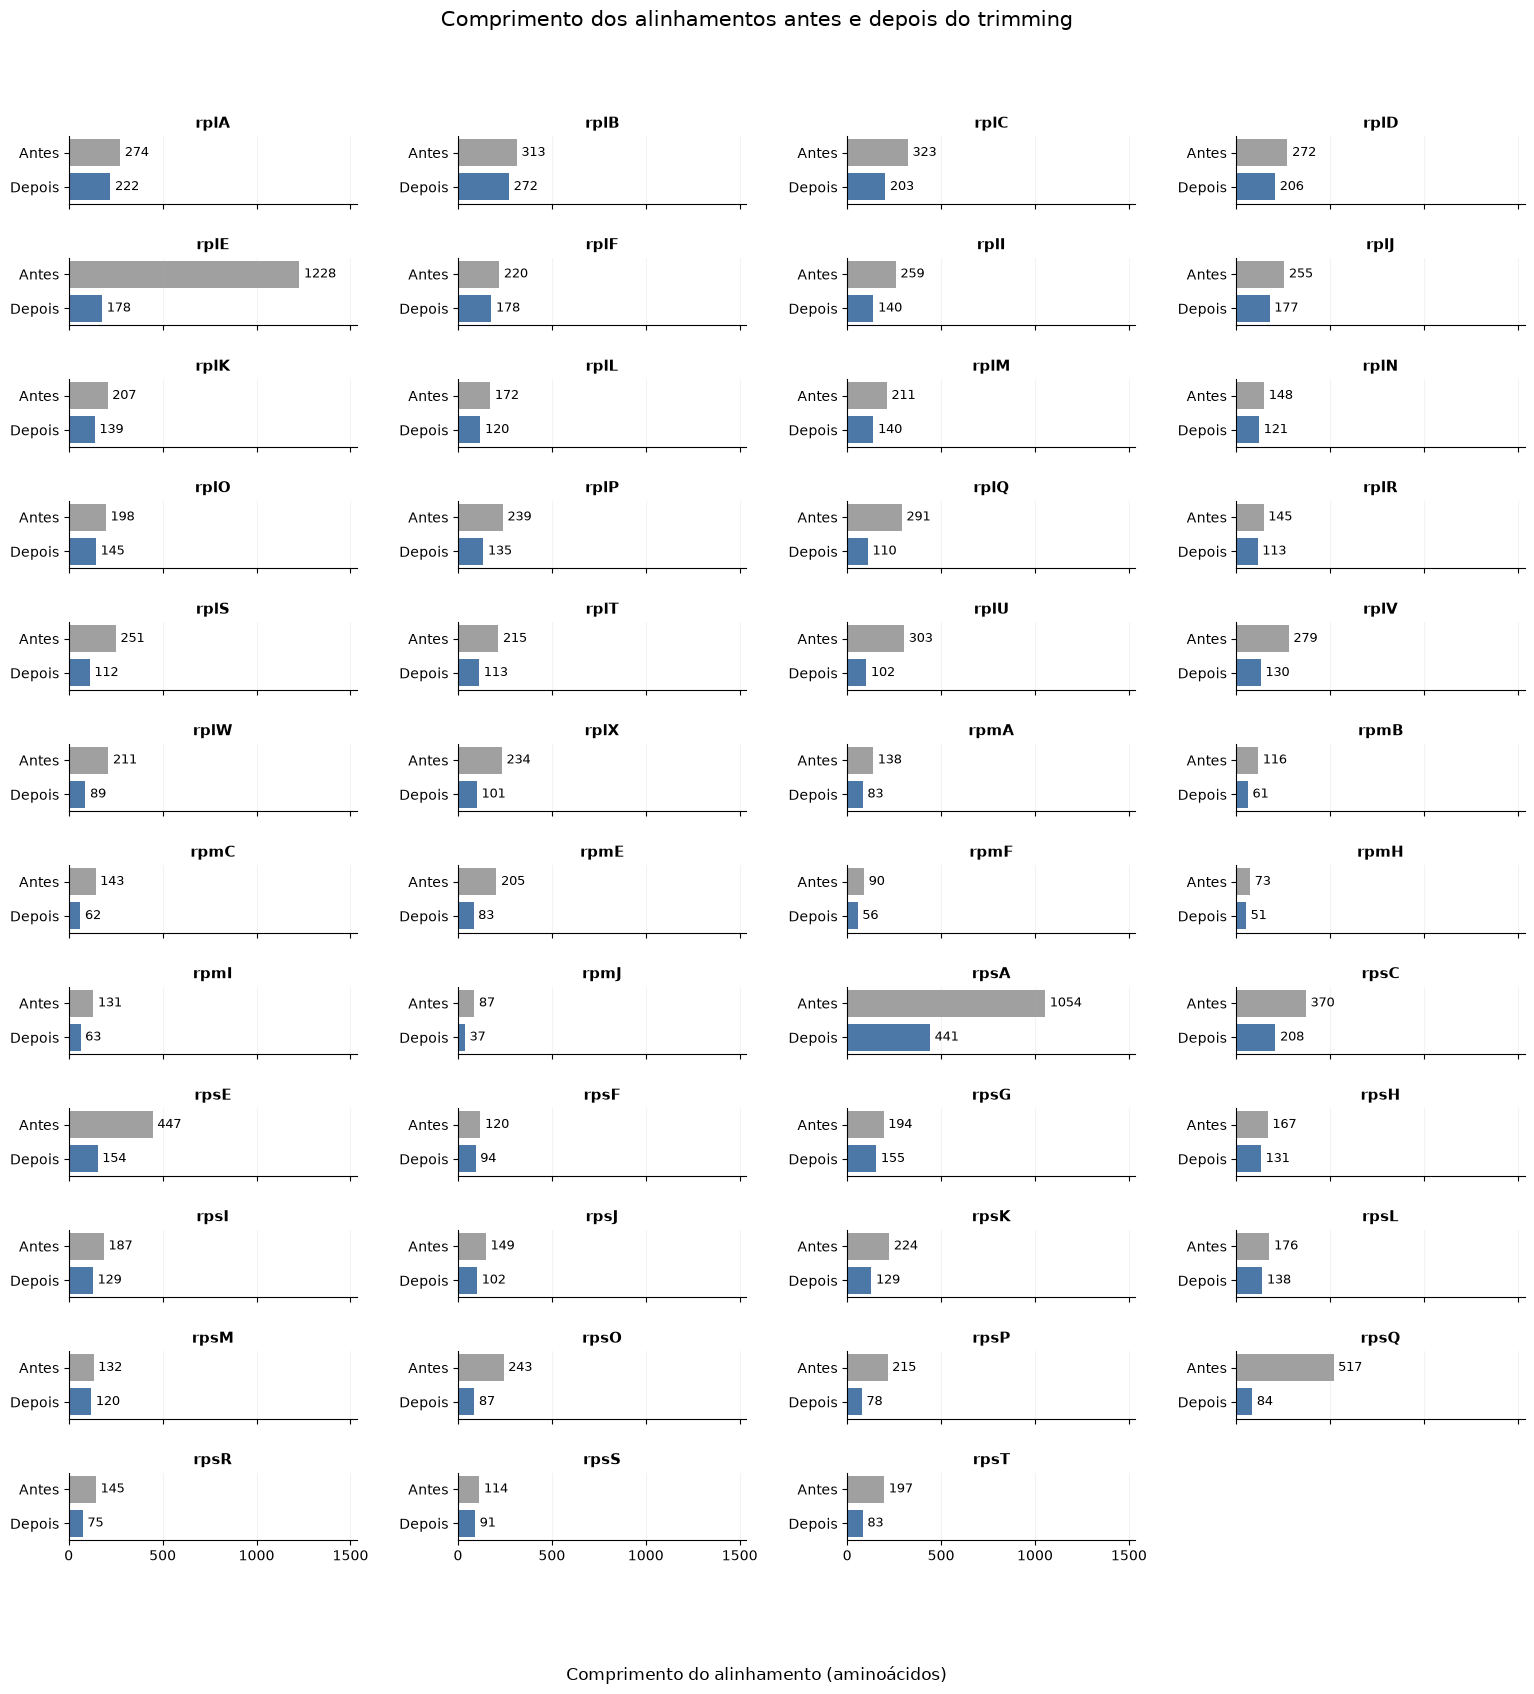

In [3]:
plot_df = summary.sort_index()

ncols = 4
nrows = math.ceil(len(plot_df) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 1.5), sharex=True, squeeze=False)
max_length = plot_df["posicoes_antes"].max()

for ax, (marker, row) in zip(axes.flat, plot_df.iterrows()):
    values = [row.posicoes_antes, row.posicoes_depois]
    ax.barh(["Antes", "Depois"], values, color=["#A0A0A0", "#4C78A8"])
    ax.invert_yaxis()
    ax.set_xlim(0, max_length * 1.25)
    ax.set_title(marker, fontsize=11, fontweight="bold")
    for i, value in enumerate(values):
        ax.text(value + max_length * 0.02, i, f"{int(value)}", va="center", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.15)

for ax in axes.flat[len(plot_df):]:
    ax.set_visible(False)

fig.supxlabel("Comprimento do alinhamento (aminoácidos)", y=0.02)
fig.suptitle("Comprimento dos alinhamentos antes e depois do trimming", fontsize=15, y=0.95)
fig.subplots_adjust(left=0.07, right=0.98, top=0.88, bottom=0.10, hspace=0.8, wspace=0.35)
plt.show()


## 3. Inspecionando os alinhamentos

Escolha um marcador **antes** e **depois** do trimAl e compare. Comece por `rplU`.

- **Mapa de gaps** mostra o alinhamento inteiro: azul é aminoácido, laranja é gap.
- **Resíduos (janela)** mostra os aminoácidos de um trecho, coloridos por propriedade físico-química. Colunas com a mesma cor de cima a baixo são regiões conservadas.
- A concatenação dos 46 marcadores também está na lista.

Este panorama mostra o que o trimAl removeu, mas não substitui a inspeção de homologia, possíveis paralogias e anotações individuais.

**Importante:** depois do aparo, a posição 50 de um alinhamento não corresponde à posição 50 do outro. Compare tamanhos e padrões, não coordenadas.


In [4]:
def fontes_ribossomais():
    fontes = {}
    for m in sorted(selribs):
        fontes[f'{m} — antes do trimAl'] = selribs[m]
        fontes[f'{m} — após o trimAl'] = trimribs[m]
    fontes['Concatenação (46 marcadores)'] = ribconcat
    exportados = arquivos_de_alinhamento(RESULT_DIR)          # FASTAs exportados abaixo
    fontes.update({k: v for k, v in exportados.items() if k.endswith(('_aligned.fasta', '_trimmed.fasta'))})
    return fontes

display(visualizador(fontes_ribossomais))


## 4. Por que `rpmH` ficou de fora?

O marcador `rpmH` foi recuperado em poucos genomas em comparação com a maioria dos demais marcadores. **Por sua cobertura esparsa, foi excluído do alinhamento concatenado**, evitando uma quantidade elevada de posições sem dados para muitos táxons.

A baixa cobertura observada pode refletir dificuldades de anotação, detecção ou agrupamento de homólogos, além de diferenças biológicas; a tabela isoladamente não identifica a causa.

In [5]:
display(summary.loc[['rpmH']].round(2))
print('Mediana da cobertura dos demais marcadores (%):',
      round(summary.drop(index='rpmH')['cobertura_%'].median(), 1))

,genomas,cobertura_%,posicoes_antes,posicoes_depois,gaps_antes_%,gaps_depois_%
marcador,,,,,,
rpmH,147,64.19,73,51,38.88,12.87


Mediana da cobertura dos demais marcadores (%): 99.6


## 5. Conferindo a concatenação real

O arquivo `ribconcat_df.pkl` guarda as 229 sequências de proteínas concatenadas, além de colunas `id_NOMEDOMARCADOR` e `orthogroup_NOMEDOMARCADOR`, utilizadas para rastrear a origem. O marcador inicial `rplU` é representado nas colunas principais. Abaixo verificamos o comprimento da concatenação de **46 marcadores** (com exclusão de `rpmH`).


In [6]:
concat_df = ribconcat
explicit_markers = {col.removeprefix('id_') for col in concat_df if col.startswith('id_')}
concat_markers = {'rplU'} | explicit_markers
excluded_markers = set(trimribs) - concat_markers
print('Genomas:', concat_df.assembly.nunique())
print('Marcadores concatenados:', len(concat_markers))
print('Marcadores excluídos:', sorted(excluded_markers))
aligned_lengths = concat_df.sequence.astype(str).str.len()
assert aligned_lengths.nunique() == 1, 'Concatenação com comprimentos diferentes!'
observed_len = int(aligned_lengths.iloc[0])
expected_len = sum(int(metrics(trimribs[m])['posicoes']) for m in concat_markers)
print('Comprimento observado:', observed_len)
print('Soma das partes:', expected_len)
assert observed_len == expected_len
assert excluded_markers == {'rpmH'}, 'Confira se a lista de exclusões mudou.'


Genomas: 229
Marcadores concatenados: 46
Marcadores excluídos: ['rpmH']
Comprimento observado: 5990
Soma das partes: 5990


## 6. Panorama da concatenação e limites entre marcadores

O mapa mostra os gaps (laranja) distribuídos pelos 229 genomas ao longo do alinhamento concatenado. As linhas verticais indicam **limites calculados a partir do comprimento dos 46 marcadores aparados**, excluindo `rpmH`.

**Nota de auditoria:** a soma dos comprimentos é verificada automaticamente. Para interpretar o nome de cada bloco como correspondente ao marcador na concatenação, a ordem de `trimribs` precisa ser a mesma usada na concatenação original; a igualdade do comprimento total, sozinha, não comprova a ordem.

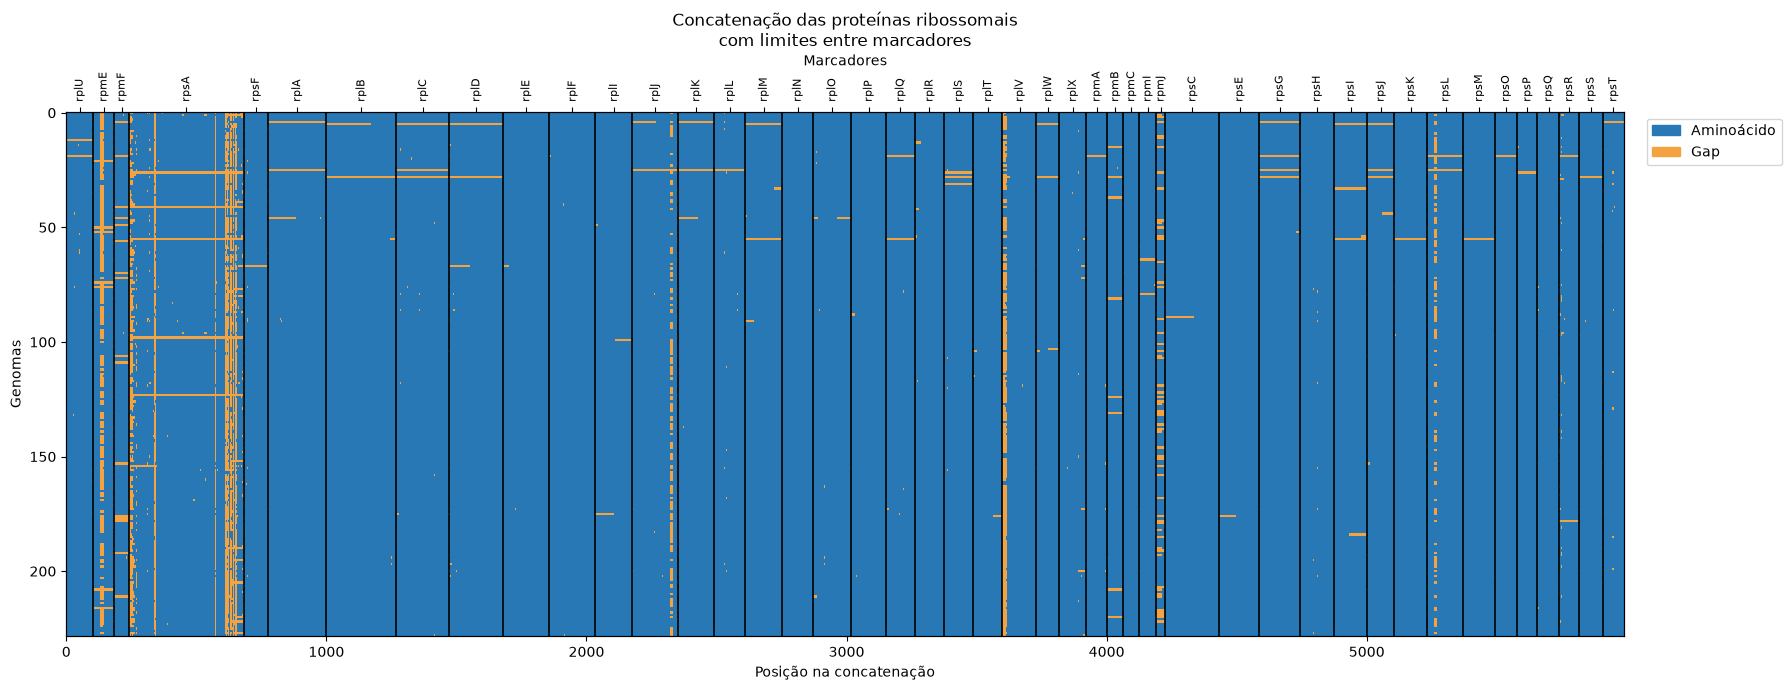

In [7]:
concat_df = ribconcat

# Comprimento de cada marcador aparado, na ordem de `trimribs`, sem rpmH.
marker_lengths = [(m, metrics(df)['posicoes']) for m, df in trimribs.items() if m != 'rpmH']
marker_names = [m for m, _ in marker_lengths]
marker_ends = np.cumsum([l for _, l in marker_lengths])
marker_starts = np.concatenate(([0], marker_ends[:-1]))
marker_mids = (marker_starts + marker_ends) / 2
assert marker_ends[-1] == observed_len  # conferido na célula anterior

gapmat = np.array([list(s) for s in concat_df['sequence']]) == '-'

fig, ax = plt.subplots(figsize=(18, 7))
ax.imshow(gapmat, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#2878B5", "#F4A340"]))
ax.set(xlabel="Posição na concatenação", ylabel="Genomas",
       title="Concatenação das proteínas ribossomais\ncom limites entre marcadores")
for x in marker_ends[:-1]:   # a última coincide com o fim da matriz
    ax.axvline(x - 0.5, color="black", lw=1.2)

top = ax.twiny()
top.set_xlim(ax.get_xlim())
top.set_xticks(marker_mids)
top.set_xticklabels(marker_names, rotation=90, fontsize=8)
top.set_xlabel("Marcadores")
ax.legend(handles=[Patch(color="#2878B5", label="Aminoácido"), Patch(color="#F4A340", label="Gap")],
          loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


## Exportar alinhamentos

Para abrir um marcador em outro programa (AliView, por exemplo), exporte-o como FASTA. Os arquivos vão para `resultados/`.


In [8]:
marker_export = widgets.Dropdown(options=sorted(selribs), value='rplU' if 'rplU' in selribs else None,
                                 description='Marcador:', layout=widgets.Layout(width='300px'))
which_export = widgets.Dropdown(options=[('Antes do trimAl', 'before'), ('Depois do trimAl', 'after'),
                                         ('Ambos', 'both')], value='after',
                                description='Exportar:', layout=widgets.Layout(width='300px'))
export_button = widgets.Button(description='Exportar FASTA', icon='save', button_style='success')
export_out = widgets.Output()

def export_fasta(_):
    with export_out:
        clear_output(wait=True)
        m = marker_export.value
        chosen = {'before': [('aligned', selribs[m])], 'after': [('trimmed', trimribs[m])],
                  'both': [('aligned', selribs[m]), ('trimmed', trimribs[m])]}[which_export.value]
        for suffix, df in chosen:
            records = [SeqRecord(Seq(str(row.sequence)), id=str(row.assembly), description='')
                       for row in df.dropna(subset=['sequence']).itertuples()]
            outfile = RESULT_DIR / f'{m}_{suffix}.fasta'
            SeqIO.write(records, outfile, 'fasta')
            print(f'✓ {outfile.relative_to(PROJECT)}: {len(records)} sequências')

export_button.on_click(export_fasta)
display(widgets.VBox([widgets.HBox([marker_export, which_export, export_button]), export_out]))
